# Few-Shot CLIP Adaptation on Oxford Flowers102

## Objective
This project explores few-shot learning techniques to adapt CLIP for improved performance on base classes while maintaining generalization to novel classes. I develop and compare multiple adaptation strategies using only 10 training samples per class, with the goal of achieving substantial base-class improvements while minimizing performance degradation on unseen (novel) classes.

## Dataset
**Oxford Flowers102** is a fine-grained classification benchmark containing 102 flower classes. For this study, classes are partitioned into two disjoint sets:
- **Base classes**: 51 classes (training distribution)
- **Novel classes**: 51 classes (test/generalization distribution)

Each base class has only 10 available training samples, creating a challenging few-shot setting.

## Evaluation Metrics
Model performance is assessed using three complementary metrics:

1. **Base Accuracy**: Classification accuracy on the 51 base classes (training distribution)
2. **Novel Accuracy**: Classification accuracy on the 51 novel classes (generalization test)
3. **Harmonic Mean**: The harmonic mean of base and novel accuracies, providing a balanced measure that penalizes large discrepancies between the two

### Evaluation Strategy
All adapted models are compared against the baseline **pretrained CLIP model** (zero-shot performance):
- **Primary goal**: Increase base accuracy substantially
- **Secondary goal**: Maintain novel accuracy close to the baseline, allowing only minimal degradation
- **Success criterion**: Achieve a higher harmonic mean than the baseline, indicating overall improvement

This evaluation framework ensures that improvements on base classes do not come at the cost of catastrophic forgetting or poor generalization to novel classes.

## Setup and Model Loading
I install the OpenAI CLIP library and load the `ViT-B/16` model as the base for zero-shot evaluation and subsequent adaptation.

In [1]:
# Install CLIP if not already present
%pip install openai_clip

import torch
import torchvision
import clip
from tqdm import tqdm

device = "cuda" if torch.cuda.is_available() else "cpu"
# available models = ['RN50', 'RN101', 'RN50x4', 'RN50x16', 'RN50x64', 'ViT-B/32', 'ViT-B/16', 'ViT-L/14', 'ViT-L/14@336px']
model_clip, preprocess = clip.load("ViT-B/16", device=device)

# 'preprocess' contains CLIP's pre-defined augmentations
preprocess

Note: you may need to restart the kernel to use updated packages.


/opt/conda/lib/python3.12/site-packages/clip/clip.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import packaging


Compose(
    Resize(size=224, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    <function _convert_image_to_rgb at 0x7ff03ec2d9e0>
    ToTensor()
    Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))
)

## Reproducibility
To ensure consistent results across runs, I set random seeds for all sources of randomness: Python's random module, NumPy, PyTorch CPU, and CUDA. This guarantees that the experiments can be reproduced with identical outcomes.

In [2]:
import torch.nn as nn
import torch.optim as optim
import numpy as np
import random

def set_seed(seed=123):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

SEED = 123
set_seed(SEED)

## Dataset Preparation
The Oxford Flowers102 dataset is split into base and novel classes (51 classes each). I use the `preprocess` function provided by CLIP to ensure images are correctly formatted for the encoder.

In [3]:
# Load Flowers102 dataset
def get_data(data_dir="./data", transform=None):
    train = torchvision.datasets.Flowers102(root=data_dir, split="train", download=True, transform=transform)
    val = torchvision.datasets.Flowers102(root=data_dir, split="val", download=True, transform=transform)
    test = torchvision.datasets.Flowers102(root=data_dir, split="test", download=True, transform=transform)
    return train, val, test

# Split classes into base and novel (half-half)
def base_novel_categories(dataset):
    all_classes = set(dataset._labels)
    num_classes = len(all_classes)
    base_classes = list(range(num_classes))[:num_classes//2]
    novel_classes = list(range(num_classes))[num_classes//2:]
    return base_classes, novel_classes

# Split dataset into base and novel subsets based on class labels
def split_data(dataset, base_classes):
    base_categories_samples = []
    novel_categories_samples = []
    base_set = set(base_classes)

    for sample_id, label in enumerate(dataset._labels):
        if label in base_set:
            base_categories_samples.append(sample_id)
        else:
            novel_categories_samples.append(sample_id)

    base_dataset = torch.utils.data.Subset(dataset, base_categories_samples)
    novel_dataset = torch.utils.data.Subset(dataset, novel_categories_samples)
    return base_dataset, novel_dataset

# Setup dataset
train_set, val_set, test_set = get_data(transform=preprocess)
base_classes, novel_classes = base_novel_categories(train_set)
train_base, _ = split_data(train_set, base_classes)
val_base, _ = split_data(val_set, base_classes)
test_base, test_novel = split_data(test_set, base_classes)

# Hard-coded class names for printing in natural language
CLASS_NAMES = ["pink primrose", "hard-leaved pocket orchid", "canterbury bells", "sweet pea", "english marigold", "tiger lily", "moon orchid", "bird of paradise", "monkshood", "globe thistle", "snapdragon", "colt's foot", "king protea", "spear thistle", "yellow iris", "globe-flower", "purple coneflower", "peruvian lily", "balloon flower", "giant white arum lily", "fire lily", "pincushion flower", "fritillary", "red ginger", "grape hyacinth", "corn poppy", "prince of wales feathers", "stemless gentian", "artichoke", "sweet william", "carnation", "garden phlox", "love in the mist", "mexican aster", "alpine sea holly", "ruby-lipped cattleya", "cape flower", "great masterwort", "siam tulip", "lenten rose", "barbeton daisy", "daffodil", "sword lily", "poinsettia", "bolero deep blue", "wallflower", "marigold", "buttercup", "oxeye daisy", "common dandelion", "petunia", "wild pansy", "primula", "sunflower", "pelargonium", "bishop of llandaff", "gaura", "geranium", "orange dahlia", "pink-yellow dahlia?", "cautleya spicata", "japanese anemone", "black-eyed susan", "silverbush", "californian poppy", "osteospermum", "spring crocus", "bearded iris", "windflower", "tree poppy", "gazania", "azalea", "water lily", "rose", "thorn apple", "morning glory", "passion flower", "lotus", "toad lily", "anthurium", "frangipani", "clematis", "hibiscus", "columbine", "desert-rose", "tree mallow", "magnolia", "cyclamen", "watercress", "canna lily", "hippeastrum", "bee balm", "ball moss", "foxglove", "bougainvillea", "camellia", "mallow", "mexican petunia", "bromelia", "blanket flower", "trumpet creeper", "blackberry lily"]
base_class_names = [CLASS_NAMES[i] for i in base_classes]
novel_class_names = [CLASS_NAMES[i] for i in novel_classes]


## Evaluation Function
I define a reusable evaluation function that computes accuracy on a given dataset. The function encodes text prompts for all categories, then compares image embeddings against text embeddings using cosine similarity to determine predictions.

In [4]:
# Do not consider gradients because nothing is trained here, only evaluated
@torch.no_grad()
def eval(model, dataset, categories, batch_size, device, label=""):
    # Set the model in evaluation mode
    model.eval()

    # Remap labels into a contiguous set starting from zero
    # this ensures that if I am working with a subset of classes (e.g., only some class ids from 
    # the full dataset), the labels are correctly mapped to [0, len(categories)-1] to allow for 
    # matching indices between text features and image features
    contig_cat2idx = {cat: idx for idx, cat in enumerate(categories)}

    # Here I apply the standard CLIP template used for oxford flowers to all categories
    # and immediately tokenize each sentence (convert natural language into numbers)
    text_inputs = clip.tokenize(
        [f"a photo of a {CLASS_NAMES[c]}, a type of flower." for c in categories]
    ).to(device)

    # Since the text features are shared for all images, I can encode them outside the evaluation loop
    text_features = model.encode_text(text_inputs)
    # Normalize the features (standard practice with CLIP)
    text_features /= text_features.norm(dim=-1, keepdim=True)

    # Dataloader creation
    dataloader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=2)
    
    # Evaluation loop
    correct_predictions = 0 # Counter for correct predictions used to compute accuracy
    for image, target in tqdm(dataloader, desc=label):
        # Map the categories ids to the [0, len(categories)-1] id used in this evaluation round.
        # Notice that labels needs to be .long() in pytorch
        target = torch.Tensor([contig_cat2idx[t.item()] for t in target]).long()

        # Move data to the proper device
        image, target = image.to(device), target.to(device)

        # Forward image through CLIP image encoder and normalize
        image_features = model.encode_image(image)
        image_features /= image_features.norm(dim=-1, keepdim=True)

        # Compute cosine similarity between image and text features
        # Compute the argmax for every row (image) to get the predicted class
        predicted_class = (image_features @ text_features.T).argmax(dim=-1)
        # Check which classes are correctly predicted, and sum them (False == 0, True == 1)
        correct_predictions += (predicted_class == target).sum().item()

    # Compute the accuracy
    accuracy = correct_predictions / len(dataset)
    return accuracy

## Zero-Shot Evaluation
I evaluate the pre-trained CLIP model without any fine-tuning. This serves as the baseline performance metric for both base and novel classes.

In [5]:
# Execute evaluation with reference naming conventions
base_accuracy = eval(model=model_clip, dataset=test_base, categories=base_classes, batch_size=128, device=device, label="🧠 Zero-shot evaluation on Base Classes")
novel_accuracy = eval(model=model_clip, dataset=test_novel, categories=novel_classes, batch_size=128, device=device, label="🧠 Zero-shot evaluation on Novel Classes")

print()
print(f"🔍 Base classes accuracy: {base_accuracy*100:.2f}%")
print(f"🔍 Novel classes accuracy: {novel_accuracy*100:.2f}%")

🧠 Zero-shot evaluation on Novel Classes: 100%|██████████| 29/29 [00:14<00:00,  1.95it/s]


🔍 Base classes accuracy: 71.33%
🔍 Novel classes accuracy: 78.24%


## Harmonic Mean
Few-Shot Adaptation papers usually report the Harmonic Mean.
The harmonic mean tends to mitigate the impact of large outliers (base accuracy) and aggravate the impact of small ones (novel accuracy).
Thus, achieving very high base accuracies at the expense of novel accuracy will be penalized by the HM.

In [6]:
def harmonic_mean(base_accuracy, novel_accuracy):
    numerator = 2
    denominator = 1 / base_accuracy + 1 / novel_accuracy
    hm = numerator / denominator
    return hm

print(f"🔍 Harmonic Mean: {harmonic_mean(base_accuracy, novel_accuracy)*100:.2f}%")

🔍 Harmonic Mean: 74.62%


## Few-Shot Adaptation: Context Optimization (CoOp)

To perform the few-shot adaptation, I decided to start and focus on **CoOp (Context Optimization)**, a method for learning task-specific prompts to optimize CLIP's performance on downstream tasks.

CoOp works by learning the prompt to attach to the labels instead of hardcoding it, reaching better results than any other manual prompting techniques.

### Reference
Zhou, K., Yang, J., Loy, C. C., & Liu, Z. (2022). Learning to prompt for vision-language models. *International Journal of Computer Vision*, 130(9), 2337–2348. https://doi.org/10.1007/s11263-022-01653-1

## Training Modes for CoOp

CoOp can be trained in two modes:

- **Class-agnostic**: learns a single prompt shared by all classes, making transfer to novel classes straightforward.

- **Class-specific**: learns one prompt per class; often boosts base-class accuracy but can overfit and hurt generalization, and the transfer to novel categories is not straightforward.



The original CoOp paper does not address base-to-novel generalization, so I explored additional strategies to make it work in this setting.

I initially implemented **class-agnostic prompts** because they can be directly applied to novel classes without modification.

However, since **class-specific prompts** achieve superior performance on base classes but cannot be directly applied to novel classes, I tried a **mixed approach**: I train class-specific prompts on base classes, and then use the mean of these prompts for the novel classes.

In [7]:
class CoOpModel(nn.Module):
    def __init__(self, clip_model, base_class_names, n_ctx=16, ctx_init=None, class_specific=False, device='cuda'):
        super().__init__()
        self.clip_model = clip_model
        self.device = device
        self.base_class_names = base_class_names

        # Dictionary for quick lookup (Class Name -> Index)
        self.base_name_to_idx = {name: i for i, name in enumerate(base_class_names)}
        
        self.n_cls = len(base_class_names)
        self.n_ctx = n_ctx
        self.class_specific = class_specific
        self.dtype = clip_model.dtype
        
        # Get text encoder dimensions (from original CLIP model)
        ctx_dim = clip_model.ln_final.weight.shape[0]
        
        # Initialization of Context Vectors
        if ctx_init:
            # If an initial context is provided, use it to initialize the context vectors
            # Replace underscores with spaces for proper tokenization
            ctx_init = ctx_init.replace("_", " ")

            # Tokenize the initial context and extract the corresponding embeddings from CLIP's token embedding layer
            tok = clip.tokenize(ctx_init).to(device)
            with torch.no_grad():
                embedding = clip_model.token_embedding(tok).type(self.dtype)
            
            # Find the position of the end-of-text token to determine context length
            eot_pos = tok[0].argmax(dim=-1).item()
            self.n_ctx = max(eot_pos - 1, 1)

            # Extract the context vectors from the token embeddings
            ctx_vectors = embedding[0, 1 : self.n_ctx + 1, :]

            # Expand context vectors if class-specific (i.e., one per class)
            if class_specific:
                ctx_vectors = ctx_vectors.unsqueeze(0).expand(self.n_cls, -1, -1)
            
            # Store the prompt prefix string for later use
            self.prompt_prefix_str = ctx_init
        else:
            # If no initial context is provided, initialize randomly
            if class_specific:
                # If class-specific, create a separate context vector for each class
                ctx_vectors = torch.empty(self.n_cls, self.n_ctx, ctx_dim, dtype=self.dtype).to(device)
            else:
                # If class-agnostic, create a single context vector
                ctx_vectors = torch.empty(self.n_ctx, ctx_dim, dtype=self.dtype).to(device)
            
            # Initialize context vectors with normal distribution
            nn.init.normal_(ctx_vectors, std=0.02)

            # Store the prompt prefix string for later use
            self.prompt_prefix_str = " ".join(["X"] * self.n_ctx)
        
        # Store context vectors as a learnable parameter
        self.ctx = nn.Parameter(ctx_vectors)

    def _get_context_vectors(self, class_names):
        """
        This function selects the appropriate context vectors based on the provided class names.
        If the model is class-specific, it checks each class name:
        - If the class is a base class, it uses its specific learned context vector.
        - If the class is a novel class, it uses the average of all learned context vectors.
        If the model is class-agnostic, it simply returns the shared context vector for all classes (no change needed).
        """
        n_input_cls = len(class_names)
        
        if self.class_specific:
            # If Class Specific: I need to check EACH class name

            # I compute the mean context vector (to use for Novel classes)
            #    Shape: [n_ctx, dim]
            mean_ctx = self.ctx.mean(dim=0) 
            
            # For each class, decide which context vector to use
            selected_vectors = []
            for name in class_names:
                # Check if the class is a Base Class (training) or a Novel Class
                if name in self.base_name_to_idx:
                    # If it is a Base Class: use its specific learned vector
                    idx = self.base_name_to_idx[name]
                    selected_vectors.append(self.ctx[idx])
                else:
                    # If it is a Novel Class: use the mean context vector
                    selected_vectors.append(mean_ctx)
            
            # Return stacked selected vectors (for each class there is a context vector)
            return torch.stack(selected_vectors)

        else:
            # If Class Agnostic: return the shared context vector for all classes
            ctx = self.ctx

            # Create batch dimension if necessary and expand with the number of input classes
            if ctx.dim() == 2:
                ctx = ctx.unsqueeze(0)
            return ctx.expand(n_input_cls, -1, -1)

    def encode_text(self, class_names=None):
        """
        This function encodes text prompts using the CLIP text encoder, incorporating the context vectors.
        """

        # Use base class names if none are provided
        if class_names is None:
            class_names = self.base_class_names
            
        # Get the appropriate context vectors (Specific or Averaged) depending on class names and logic
        ctx = self._get_context_vectors(class_names)
        
        # Create static prompts
        prompts = [self.prompt_prefix_str + " " + name for name in class_names]
        tokenized_prompts = torch.cat([clip.tokenize(p) for p in prompts]).to(self.device)
        
        # Extract embeddings from the static tokens
        with torch.no_grad():
            embedding = self.clip_model.token_embedding(tokenized_prompts).type(self.dtype)
        
        # Insert context vectors into the token embeddings
        token_prefix = embedding[:, :1, :]
        token_suffix = embedding[:, 1 + self.n_ctx :, :]
        
        x = torch.cat([token_prefix, ctx, token_suffix], dim=1)

        # Forward pass through CLIP's text encoder
        x = x + self.clip_model.positional_embedding.type(self.dtype)
        x = x.permute(1, 0, 2)
        x = self.clip_model.transformer(x)
        x = x.permute(1, 0, 2)
        x = self.clip_model.ln_final(x).type(self.dtype)

        # Extract features from the end-of-text token
        eot_indices = tokenized_prompts.argmax(dim=-1)
        x = x[torch.arange(x.shape[0]), eot_indices] @ self.clip_model.text_projection

        # Return the final text features
        return x

    def get_ctx_info(self):
        """
        This function returns information about the context vectors used in the model.
        """
        return {
            "mode": "Class-specific" if self.class_specific else "Class-agnostic",
            "n_ctx": self.n_ctx,
            "ctx_shape": tuple(self.ctx.shape),
            "base_classes": len(self.base_class_names)
        }

In [8]:
def train_coop(coop_model, train_dataset, val_dataset, categories, epochs=50, batch_size=32, lr=0.002):
    """Train CoOp model on base categories."""
    
    device = coop_model.device
    
    # Freeze CLIP parameters, because I only want to train the context vectors
    for param in coop_model.clip_model.parameters():
        param.requires_grad = False
    
    # Optimize only context vectors
    optimizer = optim.SGD([coop_model.ctx], lr=lr, momentum=0.9, weight_decay=5e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    
    # Dataloader creation
    train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
    val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2)
    
    # Remap labels into a contiguous set starting from zero for training and validation
    contig_cat2idx = {cat: idx for idx, cat in enumerate(categories)}
    
    best_val_acc = 0
    best_ctx = None
    
    # Training loop
    for epoch in range(epochs):
        coop_model.train()
        train_loss = 0
        train_correct = 0
        train_total = 0
        
        # Training batches
        for images, targets in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} [Train]", leave=False):
            
            # Map targets to contiguous indices (for proper loss computation)
            targets = torch.tensor([contig_cat2idx[t.item()] for t in targets]).long().to(device)
            images = images.to(device)
            
            # Zero gradients (in order to not accumulate gradients from previous steps)
            optimizer.zero_grad()
            
            # Encode Text: In this case I want to use the base classes so I do not pass any argument
            text_features = coop_model.encode_text()
            text_features = text_features / text_features.norm(dim=-1, keepdim=True)
            
            # Encode Image: Using the CLIP image encoder to get image features
            image_features = coop_model.clip_model.encode_image(images)
            image_features = image_features / image_features.norm(dim=-1, keepdim=True)
            
            # Compute logits and loss
            # Use the standard CLIP scaling factor
            logit_scale = coop_model.clip_model.logit_scale.exp()
            logits = logit_scale * image_features @ text_features.t()
            
            loss = nn.CrossEntropyLoss()(logits, targets)
            loss.backward()
            optimizer.step()
            
            # Accumulate loss and compute training accuracy for monitoring
            train_loss += loss.item()
            _, predicted = logits.max(1)
            train_total += targets.size(0)
            train_correct += predicted.eq(targets).sum().item()
        
        # Validation
        coop_model.eval()
        val_correct = 0
        val_total = 0
        
        with torch.no_grad():
            # Pre-compute text features per validation (using always base classes)
            text_features = coop_model.encode_text()
            text_features = text_features / text_features.norm(dim=-1, keepdim=True)
            
            for images, targets in val_loader:
                targets = torch.tensor([contig_cat2idx[t.item()] for t in targets]).long().to(device)
                images = images.to(device)
                
                image_features = coop_model.clip_model.encode_image(images)
                image_features = image_features / image_features.norm(dim=-1, keepdim=True)
                
                logit_scale = coop_model.clip_model.logit_scale.exp()
                logits = logit_scale * image_features @ text_features.t()
                
                _, predicted = logits.max(1)
                val_total += targets.size(0)
                val_correct += predicted.eq(targets).sum().item()
        
        val_acc = 100. * val_correct / val_total
        print(f"Epoch {epoch+1}: Train Acc: {100.*train_correct/train_total:.2f}%, Val Acc: {val_acc:.2f}%")
        
        # Save best model based on validation accuracy
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_ctx = coop_model.ctx.data.clone()
        
        # Step the learning rate scheduler
        scheduler.step()
    
    # Restore best context after training
    coop_model.ctx.data = best_ctx
    print(f"Training completed. Best Val Acc: {best_val_acc:.2f}%")
    return coop_model

In [9]:
# Create and train CoOp models for both class-agnostic and class-specific settings

# Initialize the model for class-agnostic CoOp
coop_model_agnostic = CoOpModel(
    clip_model=model_clip,
    base_class_names=base_class_names,
    n_ctx=16,
    ctx_init=None,  
    class_specific=False,
    device=device
).to(device)

print("=== Training CoOp with class_specific=False ===")
train_coop(coop_model_agnostic, train_base, val_base, base_classes, epochs=10)

print("\n" + "="*60 + "\n")

# Initialize the model for class-specific CoOp
coop_model_specific = CoOpModel(
    clip_model=model_clip,
    base_class_names=base_class_names,
    n_ctx=16,
    ctx_init=None,  
    class_specific=True,
    device=device
).to(device)

print("=== Training CoOp with class_specific=True ===")
train_coop(coop_model_specific, train_base, val_base, base_classes, epochs=10)
print("")

=== Training CoOp with class_specific=False ===


Epoch 1: Train Acc: 54.71%, Val Acc: 71.37%


Epoch 2: Train Acc: 72.94%, Val Acc: 74.71%


Epoch 3: Train Acc: 74.90%, Val Acc: 80.59%


Epoch 4: Train Acc: 80.59%, Val Acc: 87.06%


...

Epoch 6: Train Acc: 100.00%, Val Acc: 95.29%


Epoch 7: Train Acc: 100.00%, Val Acc: 94.90%


Epoch 8: Train Acc: 100.00%, Val Acc: 94.90%


Epoch 9: Train Acc: 100.00%, Val Acc: 95.10%


Epoch 10: Train Acc: 100.00%, Val Acc: 95.29%
Training completed. Best Val Acc: 95.69%



In [10]:
@torch.no_grad()
def eval_coop(coop_model, dataset, categories, batch_size, device, label=""):
    """
    Evaluate CoOp model on given dataset and categories.
    """

    # Set the model in evaluation mode
    coop_model.eval()
    
    # Remap labels into a contiguous set starting from zero
    # this ensures that if I am working with a subset of classes (e.g., only some class ids from 
    # the full dataset), the labels are correctly mapped to [0, len(categories)-1] to allow for 
    # matching indices between text features and image features
    contig_cat2idx = {cat: idx for idx, cat in enumerate(categories)}
    
    # Get category names
    category_names = [CLASS_NAMES[c] for c in categories]
    
    # Use the CoOp Learned prompts (the logic is different depending on class-specific or class-agnostic)
    text_features = coop_model.encode_text(category_names)
    text_features = text_features / text_features.norm(dim=-1, keepdim=True)
    
    # Dataloader creation
    dataloader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=2)
    
    correct = 0
    total = 0
    
    # Evaluation loop
    for images, targets in tqdm(dataloader, desc=label):
        # Map the categories ids to the [0, len(categories)-1] id used in this evaluation round.
        # Notice that labels needs to be .long() in pytorch
        targets = torch.tensor([contig_cat2idx[t.item()] for t in targets]).long().to(device)
        images = images.to(device)
        
        # Forward image through CLIP image encoder and normalize
        image_features = coop_model.clip_model.encode_image(images)
        image_features = image_features / image_features.norm(dim=-1, keepdim=True)
        
        # Compute cosine similarity between image and text features
        # Compute the argmax for every row (image) to get the predicted class
        logits = image_features @ text_features.T
        
        _, predicted = logits.max(1)
        total += targets.size(0)
        correct += predicted.eq(targets).sum().item()
    
    return correct / total

In [11]:
import pandas as pd

print("="*60)
print("=== Evaluating CoOp with class_specific=False ===")
print("="*60)

# Base Accuracy Improvement (Class-Agnostic)
base_acc_coop_agnostic = eval_coop(coop_model_agnostic, test_base, base_classes, 128, device, "CoOp Agnostic (Base)")

# Transfer to Novel Classes (Class-Agnostic)
novel_acc_coop_agnostic = eval_coop(coop_model_agnostic, test_novel, novel_classes, 128, device, "CoOp Agnostic (Novel)")

# Print Results
print(f"\n📊 Class-Agnostic Results:")
print(f"Base Accuracy: {base_acc_coop_agnostic*100:.2f}% (vs {base_accuracy*100:.2f}% Zero-shot)")
print(f"Novel Accuracy: {novel_acc_coop_agnostic*100:.2f}% (vs {novel_accuracy*100:.2f}% Zero-shot)")
print(f"Harmonic Mean: {harmonic_mean(base_acc_coop_agnostic, novel_acc_coop_agnostic)*100:.2f}%")

####################################################

print("\n" + "="*60)
print("=== Evaluating CoOp with class_specific=True ===")
print("="*60)

# Base Accuracy Improvement (Class-Specific)
base_acc_coop_specific = eval_coop(coop_model_specific, test_base, base_classes, 128, device, "CoOp Specific (Base)")

# Transfer to Novel Classes (Class-Specific)
novel_acc_coop_specific = eval_coop(coop_model_specific, test_novel, novel_classes, 128, device, "CoOp Specific (Novel)")

# Print Results
print(f"\n📊 Class-Specific Results:")
print(f"Base Accuracy: {base_acc_coop_specific*100:.2f}% (vs {base_accuracy*100:.2f}% Zero-shot)")
print(f"Novel Accuracy: {novel_acc_coop_specific*100:.2f}% (vs {novel_accuracy*100:.2f}% Zero-shot)")
print(f"Harmonic Mean: {harmonic_mean(base_acc_coop_specific, novel_acc_coop_specific)*100:.2f}%")

####################################################

print("\n" + "="*60)
print("=== Comparison Summary ===")
print("="*60)

# Create comparison dataframe
comparison_data = {
    "Configuration": ["Zero-shot", "CoOp (class_specific=False)", "CoOp (class_specific=True)"],
    "Evaluation": ["Separate", "Separate", "Separate"],
    "Base Accuracy": [
        f"{base_accuracy*100:.2f}%",
        f"{base_acc_coop_agnostic*100:.2f}%",
        f"{base_acc_coop_specific*100:.2f}%"
    ],
    "Novel Accuracy": [
        f"{novel_accuracy*100:.2f}%",
        f"{novel_acc_coop_agnostic*100:.2f}%",
        f"{novel_acc_coop_specific*100:.2f}%"
    ],
    "Harmonic Mean": [
        f"{harmonic_mean(base_accuracy, novel_accuracy)*100:.2f}%",
        f"{harmonic_mean(base_acc_coop_agnostic, novel_acc_coop_agnostic)*100:.2f}%",
        f"{harmonic_mean(base_acc_coop_specific, novel_acc_coop_specific)*100:.2f}%"
    ]
}

df = pd.DataFrame(comparison_data)
display(df)

=== Evaluating CoOp with class_specific=False ===


CoOp Agnostic (Novel): 100%|██████████| 29/29 [00:14<00:00,  2.01it/s]



📊 Class-Agnostic Results:
Base Accuracy: 91.27% (vs 71.33% Zero-shot)
Novel Accuracy: 74.67% (vs 78.24% Zero-shot)
Harmonic Mean: 82.14%

=== Evaluating CoOp with class_specific=True ===


CoOp Specific (Novel): 100%|██████████| 29/29 [00:14<00:00,  1.94it/s]


📊 Class-Specific Results:
Base Accuracy: 93.89% (vs 71.33% Zero-shot)
Novel Accuracy: 72.28% (vs 78.24% Zero-shot)
Harmonic Mean: 81.68%

=== Comparison Summary ===


,Configuration,Evaluation,Base Accuracy,Novel Accuracy,Harmonic Mean
0,Zero-shot,Separate,71.33%,78.24%,74.62%
1,CoOp (class_specific=False),Separate,91.27%,74.67%,82.14%
2,CoOp (class_specific=True),Separate,93.89%,72.28%,81.68%


As can be seen, both CoOp variants yield a substantial improvement in base accuracy. For the novel classes, however, the class-agnostic CoOp performs better. This is expected, since the context tokens learned in the agnostic setting are more generic and therefore transfer more effectively to unseen classes. Because the novel classes are still flowers, they are likely to lie close to the base classes in CLIP’s embedding space, allowing the shared context to generalize well.

In contrast, the class-specific variant relies on averaging context tokens learned independently for each base class. This average is sensitive to the relative positions of the base classes in the embedding space (i.e., if some base classes are far apart, the resulting mean may be pulled toward outliers rather than representing a broadly transferable context). As a result, it generalizes less effectively to novel classes than the class-agnostic formulation.

Despite this, both models achieve a large improvement in the harmonic mean.

### Hybrid Approach

As shown in the results above, **novel classes** perform better with the class-agnostic prompt, while **base classes** perform better with the class-specific prompt. To leverage the strengths of both approaches, I trained both models and applied them strategically:
- **Class-specific prompt** for base classes
- **Class-agnostic prompt** for novel classes

To achieve this, I create a subclass of `CoOpModel` that takes both the class-specific and class-agnostic models as inputs. I extract the learned prompts from each model and use them conditionally during inference: the class-agnostic prompt for novel classes and the class-specific prompt for base classes.

In [12]:
class HybridCoOpModel(CoOpModel):
    def __init__(self, specific_model, agnostic_model):
        # Initialize using the configuration of the specific model (I assume that clip_model, device and n_ctx are the same for both)
        super().__init__(
            clip_model=specific_model.clip_model,
            base_class_names=specific_model.base_class_names,
            n_ctx=specific_model.n_ctx,
            ctx_init=None,
            class_specific=True,
            device=specific_model.device
        )
        
        # Copy of the learned context vectors from both models
        self.ctx_specific = specific_model.ctx.detach().clone()
        self.ctx_agnostic = agnostic_model.ctx.detach().clone()
        
        # If the agnostic vector has dimension (1, n_ctx, dim), remove the batch dimension
        if self.ctx_agnostic.dim() == 3:
            self.ctx_agnostic = self.ctx_agnostic.squeeze(0)

    def _get_context_vectors(self, class_names):
        """
        Override the method to select context vectors based on class names:
        - For Base classes: use the specific learned context vector from the class-specific model.
        - For Novel classes: use the agnostic context vector from the class-agnostic model
        """
        selected_vectors = []
        for name in class_names:
            if name in self.base_name_to_idx:
                # If base class: use the specific learned vector for that class
                idx = self.base_name_to_idx[name]
                selected_vectors.append(self.ctx_specific[idx])
            else:
                # If novel class: use the shared agnostic vector
                selected_vectors.append(self.ctx_agnostic)
        
        return torch.stack(selected_vectors)

In [13]:
# Create the hybrid model
hybrid_model = HybridCoOpModel(coop_model_specific, coop_model_agnostic)

print("\n" + "="*60)
print("=== Evaluating Hybrid Model (Unified) ===")
print("="*60)

# Evaluate the hybrid model on both base and novel classes
hybrid_base_acc = eval_coop(hybrid_model, test_base, base_classes, 128, device, "Hybrid Model (Base)")
hybrid_novel_acc = eval_coop(hybrid_model, test_novel, novel_classes, 128, device, "Hybrid Model (Novel)")
hybrid_hm = harmonic_mean(hybrid_base_acc, hybrid_novel_acc)

print(f"\n📊 Hybrid Model Results:")
print(f"Base Accuracy: {hybrid_base_acc*100:.2f}%")
print(f"Novel Accuracy: {hybrid_novel_acc*100:.2f}%")
print(f"Harmonic Mean: {hybrid_hm*100:.2f}%")


=== Evaluating Hybrid Model (Unified) ===


Hybrid Model (Novel): 100%|██████████| 29/29 [00:14<00:00,  1.99it/s]


📊 Hybrid Model Results:
Base Accuracy: 93.89%
Novel Accuracy: 74.67%
Harmonic Mean: 83.19%


In [14]:
# Expand the comparison data to include the Hybrid Approach
rw_coop_weighted = {
    "Configuration": "CoOp (Hybrid)",
    "Evaluation": "Separate",
    "Base Accuracy": f"{hybrid_base_acc*100:.2f}%",
    "Novel Accuracy": f"{hybrid_novel_acc*100:.2f}%",
    "Harmonic Mean": f"{hybrid_hm*100:.2f}%"
}
df = pd.concat([df, pd.DataFrame([rw_coop_weighted])], ignore_index=True)

display(df)

,Configuration,Evaluation,Base Accuracy,Novel Accuracy,Harmonic Mean
0,Zero-shot,Separate,71.33%,78.24%,74.62%
1,CoOp (class_specific=False),Separate,91.27%,74.67%,82.14%
2,CoOp (class_specific=True),Separate,93.89%,72.28%,81.68%
3,CoOp (Hybrid),Separate,93.89%,74.67%,83.19%


### Dynamic Context

Since I observed that the class-specific prompts work really well with the base classes, I explored smarter ways to transfer the prompts to the new classes. One idea that came to mind was to use class-specific prompts and, instead of taking the standard average of prompts for novel classes, compute a more intelligent weighted average.

Since I can compute the similarity between an image and a prompt, I can use that similarity as a weight.

For each image to classify, I compute the prompt to use with that image for all novel labels by weighting each prompt based on the image's similarity to that prompt. In this way, if a novel class is very similar to a base class, the prompt learned for the base class will work well for the novel class as well.

The logic behind this is to have a sort of "attention" mechanism that focus more on the prompts that are more similar to the actual image.

Obviously this process is very inefficient because all the similarities have to be computed for each image.

In [15]:
import torch.nn.functional as F

# Dynamic CoOp Model Definition
class DynamicCoOpModel(CoOpModel):
    def __init__(self, clip_model, base_class_names, n_ctx=16, device='cuda'):
        super().__init__(
            clip_model=clip_model,
            base_class_names=base_class_names,
            n_ctx=n_ctx,
            ctx_init=None,
            # Class-specific to True because I need separate contexts for base classes, but I will use them in a dynamic way for novel classes
            class_specific=True,
            device=device
        )
        self.base_text_features = None

    def store_base_text_features(self):
        """
        Pre-compute and store text features for base classes to be used in dynamic context computation.
        """
        with torch.no_grad():
            text_features = self.encode_text(self.base_class_names)
            text_features = text_features / text_features.norm(dim=-1, keepdim=True)
            self.base_text_features = text_features.detach()

    def get_dynamic_context(self, image_features, temperature=1.5):
        """
        Calculate weighted context based on image-base_classes similarity.
        """
        if self.base_text_features is None:
            raise ValueError("Base text features not stored. Call store_base_text_features() first.")

        # Compute similarity between image features and base class text features
        similarity = image_features @ self.base_text_features.t()
        weights = F.softmax(similarity / temperature, dim=1) 
        
        # Compute dynamic context as weighted sum of base class contexts
        dynamic_ctx = torch.einsum('bk,kcd->bcd', weights, self.ctx)
        return dynamic_ctx

    def predict(self, images, target_class_names, temperature=1.5):
        """
        Hybrid Logic:
        - If the class is BASE -> Use its specific static prompt.
        - If the class is NOVEL -> Use the dynamic context weighted on the image.
        """
        
        batch_size = images.shape[0]
        device = self.device
        
        # Encode images
        image_features = self.clip_model.encode_image(images)
        image_features = image_features / image_features.norm(dim=-1, keepdim=True)

        # Determine which classes are base and which are novel
        base_indices_in_target = []
        novel_indices_in_target = []
        base_names = []
        novel_names = []

        for i, name in enumerate(target_class_names):
            if name in self.base_name_to_idx:
                base_indices_in_target.append(i)
                base_names.append(name)
            else:
                novel_indices_in_target.append(i)
                novel_names.append(name)

        # Prepare final logits tensor. I will fill this with the appropriate logits from the two branches (base and novel).
        final_logits = torch.full(
            (batch_size, len(target_class_names)), 
            float('-inf'), 
            device=device, 
            dtype=self.dtype
        )

        # Branch A: BASE CLASSES (Static and Light)
        if base_names:
            base_text_features = self.encode_text(base_names)
            base_text_features = base_text_features / base_text_features.norm(dim=-1, keepdim=True)
            
            logits_base = self.clip_model.logit_scale.exp() * image_features @ base_text_features.t()
            final_logits[:, base_indices_in_target] = logits_base

        # Branch B: NOVEL CLASSES (Dynamic and Heavier)
        if novel_names:
            n_novel = len(novel_names)
            
            # Compute dynamic context for the batch of images
            dynamic_ctx = self.get_dynamic_context(image_features, temperature)
            
            # Build prompts for novel classes
            prompts = [self.prompt_prefix_str + " " + name for name in novel_names]
            tokenized = torch.cat([clip.tokenize(p) for p in prompts]).to(device)
            with torch.no_grad():
                embedding = self.clip_model.token_embedding(tokenized).type(self.dtype)
            
            token_prefix = embedding[:, :1, :]              
            token_suffix = embedding[:, 1 + self.n_ctx :, :] 
            
            ctx_expanded = dynamic_ctx.unsqueeze(1).expand(-1, n_novel, -1, -1)
            prefix_expanded = token_prefix.unsqueeze(0).expand(batch_size, -1, -1, -1)
            suffix_expanded = token_suffix.unsqueeze(0).expand(batch_size, -1, -1, -1)
            
            x = torch.cat([prefix_expanded, ctx_expanded, suffix_expanded], dim=2)
            x = x.reshape(batch_size * n_novel, -1, x.shape[-1])
            
            x = x + self.clip_model.positional_embedding.type(self.dtype)
            x = x.permute(1, 0, 2)
            x = self.clip_model.transformer(x)
            x = x.permute(1, 0, 2)
            x = self.clip_model.ln_final(x).type(self.dtype)
            
            eot_indices = tokenized.argmax(dim=-1).repeat(batch_size)
            x = x[torch.arange(x.shape[0]), eot_indices] @ self.clip_model.text_projection
            
            text_features_novel = x.view(batch_size, n_novel, -1)
            text_features_novel = text_features_novel / text_features_novel.norm(dim=-1, keepdim=True)
            
            logits_novel = (image_features.unsqueeze(1) * text_features_novel).sum(dim=-1)
            logits_novel = logits_novel * self.clip_model.logit_scale.exp()
            
            final_logits[:, novel_indices_in_target] = logits_novel

        return final_logits

In [16]:
@torch.no_grad()
def eval_dynamic_weighted(model, dataset, categories, batch_size=16, device='cuda'):
    """
    Evaluation function for the Dynamic CoOp Model.
    """
    model.eval()
    contig_cat2idx = {cat: idx for idx, cat in enumerate(categories)}
    category_names = [CLASS_NAMES[c] for c in categories]
    
    dataloader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=2)
    correct = 0
    total = 0
    
    # Evaluation loop
    for images, targets in tqdm(dataloader, desc="Dynamic Weighted Eval"):
        images = images.to(device)
        targets = torch.tensor([contig_cat2idx[t.item()] for t in targets]).long().to(device)
        
        # Get logits using the dynamic prediction method
        logits = model.predict(images, category_names, temperature=1.5)
        
        _, predicted = logits.max(1)
        total += targets.size(0)
        correct += predicted.eq(targets).sum().item()
        
    return correct / total

In [17]:
# Initialize the Dynamic CoOp Model
dynamic_model = DynamicCoOpModel(
    clip_model=model_clip,
    base_class_names=base_class_names,
    n_ctx=16,
    device=device
).to(device)

# Load learned parameters from the class-specific CoOp model (which is already trained)
dynamic_model.load_state_dict(coop_model_specific.state_dict())

# Pre-compute base class features (keys for attention)
dynamic_model.store_base_text_features()

print("✅ Dynamic Model initialized and base features stored.")

✅ Dynamic Model initialized and base features stored.


In [18]:
# Evaluate Base classes
'''
base_acc_final = eval_dynamic_weighted(
    dynamic_model, 
    test_base, 
    base_classes, 
    batch_size=16,
    device=device
)
'''

# Since the results on base classes should be the same as the class-specific CoOp model
base_acc_final = base_acc_coop_specific

# Evaluate Novel classes using Weighted context
novel_acc_dynamic_weighted = eval_dynamic_weighted(
    dynamic_model, 
    test_novel, 
    novel_classes, 
    batch_size=16,
    device=device
)

# Calculate new Harmonic Mean
dynamic_hm = harmonic_mean(base_acc_final, novel_acc_dynamic_weighted)

# Update the final table
rw_coop_weighted = {
    "Configuration": "CoOp (Dynamic-Weighted)",
    "Evaluation": "Separate",
    "Base Accuracy": f"{base_acc_coop_specific*100:.2f}%",
    "Novel Accuracy": f"{novel_acc_dynamic_weighted*100:.2f}%",
    "Harmonic Mean": f"{dynamic_hm*100:.2f}%"
}
df = pd.concat([df, pd.DataFrame([rw_coop_weighted])], ignore_index=True)
display(df)

Dynamic Weighted Eval: 100%|██████████| 230/230 [01:52<00:00,  2.04it/s]


,Configuration,Evaluation,Base Accuracy,Novel Accuracy,Harmonic Mean
0,Zero-shot,Separate,71.33%,78.24%,74.62%
1,CoOp (class_specific=False),Separate,91.27%,74.67%,82.14%
2,CoOp (class_specific=True),Separate,93.89%,72.28%,81.68%
3,CoOp (Hybrid),Separate,93.89%,74.67%,83.19%
4,CoOp (Dynamic-Weighted),Separate,93.89%,72.36%,81.73%


I can observe that, even though this method successfully improves the accuracy on the novel classes, it is not enough to achieve a higher harmonic mean with respect to the other methods.

### Naive Approach

Across all techniques, I consistently increased base-class accuracy and the overall harmonic mean, but this came with a drop (even if small) in novel-class performance. This was an obvious consequence of the fact that during the finetuning phase the novel classes aren't viewed and considered.

This suggested a simple strategy: use CoOp (class-specific) for base classes and zero-shot CLIP for novel classes. This pairing maximizes accuracy for each group and yields the best harmonic mean.

In [19]:
# Naive Model Definition
class NaiveModel(nn.Module):
    def __init__(self, coop_model, base_class_names, device):
        super().__init__()
        self.coop_model = coop_model
        # Use the same CLIP model inside CoOp
        self.clip_model = coop_model.clip_model
        self.device = device
        
        # Set of base class names for quick lookup
        self.base_class_names_set = set(base_class_names)
        self.dtype = coop_model.dtype

    def encode_text(self, class_names):
        """
        This function encodes text prompts using a hybrid logic:
        - For Base classes: use the learned prompts from CoOp.
        - For Novel classes: use standard CLIP prompts.
        """
        
        # Identify base and novel classes
        base_indices = []
        base_names = []
        
        novel_indices = []
        novel_prompts = []
        
        # Iterate over the requested names to separate them
        for i, name in enumerate(class_names):
            if name in self.base_class_names_set:
                base_indices.append(i)
                base_names.append(name)
            else:
                novel_indices.append(i)
                # Create standard prompt for novel classes
                novel_prompts.append(f"a photo of a {name}, a type of flower.")
        
        # Container tensor for results
        dim = self.clip_model.ln_final.weight.shape[0]
        text_features = torch.zeros(len(class_names), dim, device=self.device, dtype=self.dtype)
        
        # Compute feature for base classes using CoOp learned prompts
        if base_names:
            # Reuse CoOpModel logic to extract learned prompts
            base_feats = self.coop_model.encode_text(base_names)
            text_features[base_indices] = base_feats
            
        # Compute feature for novel classes
        if novel_prompts:
            tokenized_novel = clip.tokenize(novel_prompts).to(self.device)
            with torch.no_grad():
                novel_feats = self.clip_model.encode_text(tokenized_novel)
                # Standard CLIP projection and normalization
                novel_feats = novel_feats / novel_feats.norm(dim=-1, keepdim=True)
            text_features[novel_indices] = novel_feats.type(self.dtype)
            
        return text_features

In [20]:
print("="*60)
print("=== Evaluating Naive Model ===")
print("="*60)

# Create the Naive Hybrid Model (using the class-specific CoOp model already trained)
naive_model = NaiveModel(
    coop_model=coop_model_specific, 
    base_class_names=base_class_names, 
    device=device
)

# Evaluate on Base Classes
# I can use the same evaluation function of coop since I have defined the method encode_text
naive_base_acc = eval_coop(naive_model, test_base, base_classes, 128, device, "Naive Model (Base)")

# Evaluate on Novel Classes
naive_novel_acc = eval_coop(naive_model, test_novel, novel_classes, 128, device, "Naive Model (Novel)")

# Calculate Harmonic Mean
naive_hm = harmonic_mean(naive_base_acc, naive_novel_acc)

print(f"\n📊 Naive Model Results:")
print(f"Base Accuracy: {naive_base_acc*100:.2f}%")
print(f"Novel Accuracy: {naive_novel_acc*100:.2f}%")
print(f"Harmonic Mean: {naive_hm*100:.2f}%")

# Update final results table
rw_naive = {
    "Configuration": "Naive (Hybrid)",
    "Evaluation": "Separate",
    "Base Accuracy": f"{naive_base_acc*100:.2f}%",
    "Novel Accuracy": f"{naive_novel_acc*100:.2f}%",
    "Harmonic Mean": f"{naive_hm*100:.2f}%"
}
df = pd.concat([df, pd.DataFrame([rw_naive])], ignore_index=True)
display(df)

=== Evaluating Naive Model ===


Naive Model (Novel): 100%|██████████| 29/29 [00:15<00:00,  1.90it/s]


📊 Naive Model Results:
Base Accuracy: 93.89%
Novel Accuracy: 78.24%
Harmonic Mean: 85.35%


,Configuration,Evaluation,Base Accuracy,Novel Accuracy,Harmonic Mean
0,Zero-shot,Separate,71.33%,78.24%,74.62%
1,CoOp (class_specific=False),Separate,91.27%,74.67%,82.14%
2,CoOp (class_specific=True),Separate,93.89%,72.28%,81.68%
3,CoOp (Hybrid),Separate,93.89%,74.67%,83.19%
4,CoOp (Dynamic-Weighted),Separate,93.89%,72.36%,81.73%
5,Naive (Hybrid),Separate,93.89%,78.24%,85.35%


## The Big Problem and the New Evaluation Method

Even though the previous methods perform well when checked separately on base and novel splits, a realistic deployment needs a single classifier over all 102 classes at once. Which is why I propose a new function to evaluate CLIP model, which allows to evaluate all the test set together and retrieve the results properly divided between base and novel data, ready to be inspected. 

In [21]:
@torch.no_grad()
def eval_all_unified(model, dataset, all_class_names, base_idxs, novel_idxs, batch_size, device, model_name):
    """
    Unified evaluation function that computes both Base and Novel accuracies in a single pass over the dataset.
    This function is designed to work with all model types (Zero-shot, CoOp variants, Dynamic, Naive) by handling the text feature preparation and prediction logic accordingly.
    """

    # Set model to evaluation mode
    model.eval()
    
    # Determine if the model is Dynamic (requires special handling due to its predict method)
    is_dynamic = "Dynamic" in model_name
    text_features = None

    # If not Dynamic, prepare text features in advance
    if not is_dynamic:
        # If it's a standard CLIP model (zero-shot) then use standard prompt
        if isinstance(model, clip.model.CLIP):
            prompts = [f"a photo of a {name}, a type of flower." for name in all_class_names]
            text_inputs = clip.tokenize(prompts).to(device)
            text_features = model.encode_text(text_inputs)
        # If it's a CoOp or Naive model then use its encode_text method directly
        else:
            text_features = model.encode_text(all_class_names)
        
        # Normalize text features
        text_features = text_features / text_features.norm(dim=-1, keepdim=True)

    # Dataloader
    dataloader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=2)

    # Sets for quick lookup
    base_set = set(base_idxs)
    novel_set = set(novel_idxs)

    # Counters
    correct_base, total_base = 0, 0
    correct_novel, total_novel = 0, 0

    # Evaluation loop
    for images, targets in tqdm(dataloader, desc=f"Evaluating {model_name}"):
        images = images.to(device)
        targets = targets.to(device)

        # Compute logits
        if is_dynamic:
            # The Dynamic model uses .predict() and internally handles prompt creation
            logits = model.predict(images, all_class_names)
        else:
            # Standard image encoding
            image_features = model.encode_image(images) if isinstance(model, clip.model.CLIP) else model.clip_model.encode_image(images)
            image_features = image_features / image_features.norm(dim=-1, keepdim=True)
            
            # Compute standard logits
            logit_scale = model.logit_scale.exp() if isinstance(model, clip.model.CLIP) else model.clip_model.logit_scale.exp()
            logits = logit_scale * image_features @ text_features.T

        # 3. Prediction
        predicted_class = logits.argmax(dim=-1)

        # 4. Calculate statistics (Split Base/Novel)
        for pred, true_label in zip(predicted_class.cpu().tolist(), targets.cpu().tolist()):
            if true_label in base_set:
                total_base += 1
                if pred == true_label:
                    correct_base += 1
            elif true_label in novel_set:
                total_novel += 1
                if pred == true_label:
                    correct_novel += 1

    # Calculate accuracies
    acc_base = correct_base / total_base if total_base > 0 else 0
    acc_novel = correct_novel / total_novel if total_novel > 0 else 0
    
    return acc_base, acc_novel

In [22]:
# Define all categories [0...101]
all_categories = base_classes + novel_classes

# Run the evaluation on CLIP Zero-shot
print("="*60)
print("=== Evaluating CLIP Zero-shot (Unified) ===")
print("="*60)
zero_base_acc_unified, zero_novel_acc_unified = eval_all_unified(
    model_clip,
    test_base + test_novel,
    [CLASS_NAMES[c] for c in all_categories],
    base_classes,
    novel_classes,
    batch_size=128,
    device=device,
    model_name="CLIP Zero-shot"
)

# Print Zero-shot results
print(f"Base Accuracy (eval on all): {zero_base_acc_unified*100:.2f}%")
print(f"Novel Accuracy (eval on all): {zero_novel_acc_unified*100:.2f}%")
print(f"Harmonic Mean: {harmonic_mean(zero_base_acc_unified, zero_novel_acc_unified)*100:.2f}%")

=== Evaluating CLIP Zero-shot (Unified) ===


Evaluating CLIP Zero-shot: 100%|██████████| 49/49 [00:25<00:00,  1.92it/s]

Base Accuracy (eval on all): 66.92%
Novel Accuracy (eval on all): 74.24%
Harmonic Mean: 70.39%


In [23]:
# Calculate the final Harmonic Mean for the combined evaluation
hm_separate = harmonic_mean(base_accuracy, novel_accuracy)
hm_combined = harmonic_mean(zero_base_acc_unified, zero_novel_acc_unified)

# Prepare the data for comparison
rw_combined_eval = {
    "Configuration": "Zero-shot",
    "Evaluation": "Combined",
    "Base Accuracy": f"{zero_base_acc_unified*100:.2f}%",
    "Novel Accuracy": f"{zero_novel_acc_unified*100:.2f}%",
    "Harmonic Mean": f"{hm_combined*100:.2f}%"
}
df = pd.concat([df, pd.DataFrame([rw_combined_eval])], ignore_index=True)

# Display only the Zero-shot rows to compare the two evaluation methods
df_filtered = df[(df["Configuration"] == "Zero-shot")]
display(df_filtered)

,Configuration,Evaluation,Base Accuracy,Novel Accuracy,Harmonic Mean
0,Zero-shot,Separate,71.33%,78.24%,74.62%
6,Zero-shot,Combined,66.92%,74.24%,70.39%


Expanding the search space by evaluating all classes together reduces performance. The model must distinguish among 102 categories instead of 51, which makes the task harder and lowers accuracy on both base and novel classes. Still, this is closer to a real-world setting, so from now on I will report results using the combined evaluation.

Next, I evaluate the remaining models under the combined setting.

In [24]:
print("\n" + "="*80)
print("=== FINAL COMPARISON: COMBINED EVALUATION (Real-World Scenario) ===")
print("="*80)

# Prepare list of models to evaluate (that need to be already trained)
models_list = [
    ("CoOp (Agnostic)", coop_model_agnostic),
    ("CoOp (Specific)", coop_model_specific),
    ("CoOp (Hybrid)", hybrid_model),
    ("CoOp (Dynamic)", dynamic_model),
    ("Naive (Hybrid)", naive_model)
]

results_combined = []

# All class indices (0..101)
# IMPORTANT: I use the complete test_set containing all images
all_class_names = CLASS_NAMES # The complete list of names
all_indices = list(range(len(CLASS_NAMES)))

for name, curr_model in models_list:
    acc_base, acc_novel = eval_all_unified(
        curr_model, 
        test_set, 
        all_class_names, 
        base_classes, 
        novel_classes, 
        batch_size=128, # Reduce if you get OutOfMemory with Dynamic
        device=device,
        model_name=name
    )
    
    hm = harmonic_mean(acc_base, acc_novel)
    
    results_combined.append({
        "Configuration": name,
        "Evaluation": "Combined",
        "Base Accuracy": f"{acc_base*100:.2f}%",
        "Novel Accuracy": f"{acc_novel*100:.2f}%",
        "Harmonic Mean": f"{hm*100:.2f}%"
    })
df = pd.concat([df, pd.DataFrame(results_combined)], ignore_index=True)


=== FINAL COMPARISON: COMBINED EVALUATION (Real-World Scenario) ===


Evaluating Naive (Hybrid): 100%|██████████| 49/49 [00:24<00:00,  2.03it/s]


In [25]:
# Create and display DataFrame
df_filtered = df[df["Evaluation"] == "Combined"]
display(df_filtered)

,Configuration,Evaluation,Base Accuracy,Novel Accuracy,Harmonic Mean
6,Zero-shot,Combined,66.92%,74.24%,70.39%
7,CoOp (Agnostic),Combined,77.68%,71.93%,74.69%
8,CoOp (Specific),Combined,72.91%,71.82%,72.36%
9,CoOp (Hybrid),Combined,61.18%,74.10%,67.02%
10,CoOp (Dynamic),Combined,72.75%,71.82%,72.28%
11,Naive (Hybrid),Combined,46.74%,78.18%,58.51%


As I have previously anticipated, the results performing an overall evaluation changes drastically. For instance, the _naive model_, which had the higher harmonic mean improvement (85.35%), become the worst. 

In [26]:
df_filtered = df[
    (df["Configuration"] == "Naive (Hybrid)")
]
display(df_filtered)

,Configuration,Evaluation,Base Accuracy,Novel Accuracy,Harmonic Mean
5,Naive (Hybrid),Separate,93.89%,78.24%,85.35%
11,Naive (Hybrid),Combined,46.74%,78.18%,58.51%


### Inconsistent Feature Spaces (Combined 102-Class Evaluation)

When I moved from separate evaluations to the combined 102-class scenario, the Hybrid models suffered a sharp performance drop. The root cause is feature space inconsistency.

**Standard CoOp models (Agnostic, Specific and Dynamic)**
- Operate in a single feature space.
- Use the same learned context tokens (or their averaged variant) for all classes.
- Because the feature space is consistent, base and novel classes remain comparable, yielding a strong harmonic mean that can beat zero-shot CLIP.

**Hybrid models**
- Use disjoint feature spaces.
- Apply optimized CoOp prompts for base classes, but revert to standard CLIP prompts for novel classes (or apply class-specific prompts for base classes, but class-agnostic promprs for novel ones).
- This induces a distribution shift: base-class embeddings are no longer aligned with novel-class embeddings.

**Conclusion**
Hybrid approaches that appear strong in isolation perform worse than zero-shot CLIP under a realistic, unified evaluation.

**Decision**
I will use the combined 102-class evaluation as the primary benchmark to reflect real-world performance.

# Adaptive Classification: Predicting Base vs. Novel Classes

I discard the CoOp (Hybrid) and Naive (Hybrid) approaches, which yield a worse harmonic mean than zero-shot CLIP. All other methods improve the harmonic mean, but novel-class accuracy is lower than CLIP zero-shot in every case.

My goal is to raise base-class accuracy without degrading novel-class accuracy. To do this, I look for a criterion that predicts whether an image belongs to base or novel classes, and then apply the most suitable evaluation strategy accordingly.

## The Threshold Method

I can use the similarity scores between an image and the learned CoOp *specific* prompts to infer whether the image belongs to a base or a novel class.

Intuition: for base images, the training objective encourages one prompt to score much higher than the others. For novel images, no single prompt should dominate, so the scores should be more balanced.

Method: compute similarities between the image and all class-specific prompts (learned from base classes). Let $s_1$ be the highest similarity and $s_2$ the second highest. Use the gap $\Delta = s_1 - s_2$ as a confidence signal:

- If $\Delta$ is above a threshold, predict the image is a base class.
- If $\Delta$ is at or below the threshold, predict the image is a novel class.

Routing: for predicted base classes, use CoOp prompts (stronger on base classes). For predicted novel classes, use standard CLIP (stronger on novel classes). This routing will not be perfect, but even with some errors it can improve overall performance compared to plain CLIP and earlier methods.

### Analyze the $\Delta$ values

First, compute the similarity scores between each image and all prompts, then check whether the gap between the top-1 and top-2 scores follows the base-vs-novel intuition in practice.

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import torch
from tqdm import tqdm

def get_probability_stats(model, dataset, device, temperature=5.0):
    """
    This function computes the Top-1 and Top-2 predicted probabilities and the gap between them for each image in the dataset when evaluated against the base class prompts.
    I decided to set a higher temperature (5.0) that smooths the distribution and makes it easier to see the differences in confidence between the top predictions, especially for the novel classes which I expect to have lower confidence on the base prompts.
    - If the image is a Base class, then the smoother distribution should still show a strong peak at the correct class.
    - If the image is a Novel class, then I expect lower confidence overall, and thus the gap between Top-1 and Top-2 should be smaller, indicating more uncertainty in the prediction.
    """

    # Set model to evaluation mode
    model.eval()
    
    # Use the CLIP logit scale
    logit_scale = model.clip_model.logit_scale.exp()
    
    # Get the text features of the base class prompts which will be used for all comparisons
    text_features = model.encode_text()
    text_features = text_features / text_features.norm(dim=-1, keepdim=True)
    
    # Dataloader creation
    dataloader = torch.utils.data.DataLoader(dataset, batch_size=128, shuffle=False)
    
    # Containers for statistics
    all_top1 = []
    all_top2 = []
    all_gaps = []

    # Evaluation loop
    for images, _ in tqdm(dataloader, desc="Analyzing Probabilities"):
        images = images.to(device)

        with torch.no_grad():
            # Encode images with CLIP image encoder
            image_features = model.clip_model.encode_image(images)
            image_features = image_features / image_features.norm(dim=-1, keepdim=True)
            
            # Compute logits against the base class text features
            logits = logit_scale * (image_features @ text_features.T)
            
            # Calculate probabilities
            probs = torch.softmax(logits / temperature, dim=-1)
            
            # Extract Top-1 and Top-2 probabilities for each image
            top2_probs, _ = torch.topk(probs, k=2, dim=-1)
            t1 = top2_probs[:, 0]
            t2 = top2_probs[:, 1]
            gap = t1 - t2
            
            # Store statistics
            all_top1.extend(t1.cpu().tolist())
            all_top2.extend(t2.cpu().tolist())
            all_gaps.extend(gap.cpu().tolist())
            
    return {
        "top1": np.array(all_top1),
        "top2": np.array(all_top2),
        "gap": np.array(all_gaps)
    }

In [28]:
# Execute the analysis for the class-specific CoOp model
print("Analyzing Base Classes (In-Distribution)...")
base_stats = get_probability_stats(coop_model_specific, test_base, device)

print("Analyzing Novel Classes (Out-of-Distribution vs Base Prompts)...")
novel_mismatched_stats = get_probability_stats(coop_model_specific, test_novel, device)

# Table to show the summary statistics
print("\n📊 Probability Statistics Summary:")
summary_data = {
    "Metric": ["Avg Top-1 Prob", "Avg Top-2 Prob", "Avg Prob Gap", "Median Gap"],
    "Base Classes": [
        f"{np.mean(base_stats['top1'])*100:.2f}%",
        f"{np.mean(base_stats['top2'])*100:.2f}%",
        f"{np.mean(base_stats['gap'])*100:.2f}%",
        f"{np.median(base_stats['gap'])*100:.2f}%"
    ],
    "Novel (Mismatched)": [
        f"{np.mean(novel_mismatched_stats['top1'])*100:.2f}%",
        f"{np.mean(novel_mismatched_stats['top2'])*100:.2f}%",
        f"{np.mean(novel_mismatched_stats['gap'])*100:.2f}%",
        f"{np.median(novel_mismatched_stats['gap'])*100:.2f}%"
    ]
}
display(pd.DataFrame(summary_data))

Analyzing Base Classes (In-Distribution)...


Analyzing Probabilities: 100%|██████████| 20/20 [00:22<00:00,  1.14s/it]


Analyzing Novel Classes (Out-of-Distribution vs Base Prompts)...


Analyzing Probabilities: 100%|██████████| 29/29 [00:33<00:00,  1.14s/it]


📊 Probability Statistics Summary:


,Metric,Base Classes,Novel (Mismatched)
0,Avg Top-1 Prob,16.17%,7.87%
1,Avg Top-2 Prob,6.70%,5.89%
2,Avg Prob Gap,9.47%,1.97%
3,Median Gap,8.83%,1.42%


As shown above, there is a substantial disparity in the gap distributions between base and novel categories. This difference can be exploited to determine whether an image belongs to a base or novel class.

I visualize this gap distribution graphically to better understand the separation between the two classes.

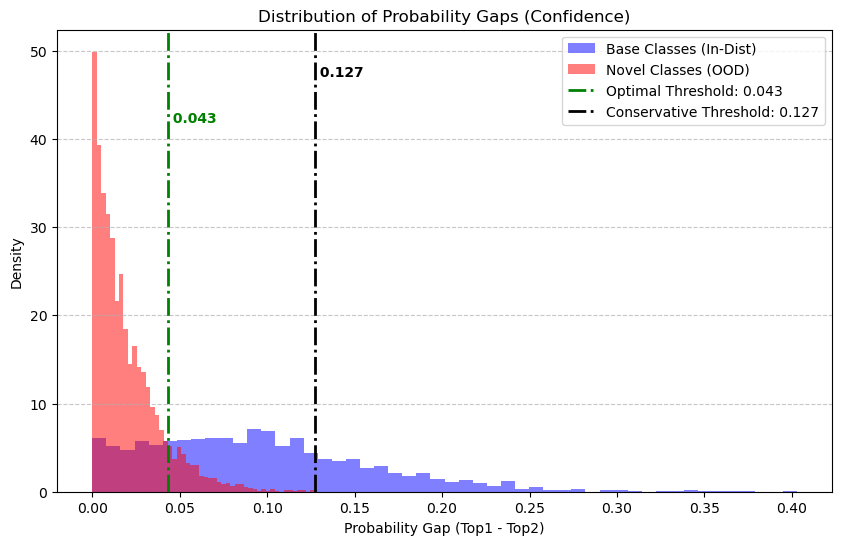

In [29]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import gaussian_kde

# Extract the confidence gap values for both datasets
gaps_base = base_stats['gap']  # Gaps for classes the model was trained on
gaps_novel = novel_mismatched_stats['gap']  # Gaps for new classes the model hasn't seen

# OPTIMAL THRESHOLD CALCULATION
# Create smooth curve representations of the distributions
# (Instead of just looking at raw data points, I create continuous curves)
kde_base = gaussian_kde(gaps_base)  # Smooth curve for known classes
kde_novel = gaussian_kde(gaps_novel)  # Smooth curve for unknown classes
x_range = np.linspace(0, 1, 1000)  # Test values from 0 to 1

# Find where the two curves cross each other
diff = kde_base(x_range) - kde_novel(x_range)  # Calculate difference between curves
# Look for where the sign flips (positive to negative or vice versa)
idx_intersection = np.argwhere(np.diff(np.sign(diff))).flatten()
intersection_val = x_range[idx_intersection[0]] if len(idx_intersection) > 0 else 0.5

# CONSERVATIVE THRESHOLD CALCULATION
# Calculate a safety threshold: the highest gap value seen in unknown classes
# (Any gap higher than this is definitely a new/unknown class)
conservative_thresh = np.max(gaps_novel)

# Create the plot
plt.figure(figsize=(10, 6))
plt.hist(gaps_base, bins=50, alpha=0.5, label='Base Classes (In-Dist)', color='blue', density=True)
plt.hist(gaps_novel, bins=50, alpha=0.5, label='Novel Classes (OOD)', color='red', density=True)
plt.axvline(intersection_val, color='green', linestyle='-.', linewidth=2, 
            label=f'Optimal Threshold: {intersection_val:.3f}')
plt.text(intersection_val, plt.ylim()[1]*0.8, f' {intersection_val:.3f}', color='green', fontweight='bold')

plt.axvline(conservative_thresh, color='black', linestyle='-.', linewidth=2, 
            label=f'Conservative Threshold: {conservative_thresh:.3f}')
plt.text(conservative_thresh, plt.ylim()[1]*0.9, f' {conservative_thresh:.3f}', color='black', fontweight='bold')

plt.title('Distribution of Probability Gaps (Confidence)')
plt.xlabel('Probability Gap (Top1 - Top2)')
plt.ylabel('Density')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()


Based on the distribution, I can observe that this criterion successfully separates **base classes** from **novel classes**. While the separation is distinct, it is not perfect, and some **overlap** (interference) remains.

In the accompanying graph, I have highlighted two critical thresholds:

- **Optimal Threshold:** This point maximizes the overall classification accuracy between novel and base categories.  
- **Conservative Threshold:** This limit is set to ensure that a novel class is **never** misclassified as a base class (zero false positives for base classes).

The **"Optimal"** threshold may not actually be ideal for this specific algorithm. If a novel class is misclassified as a base class, the **CoOp (Context Optimization)** module will be applied to it, which typically leads to a degradation in performance.

By contrast, using the **Conservative** threshold ensures that no novel class is treated as a base class. This approach guarantees that I only improve upon the baseline; I enhance the performance of base classes without the risk of damaging the results for novel ones.

While any value between these two thresholds will yield functional results, the ideal choice depends on **CoOp's performance on novel classes**:

- **If CoOp performance is poor on novel classes:** Use the **Conservative** threshold to avoid any performance drop.  
- **If CoOp is relatively robust on novel classes:** A value closer to the **Optimal** threshold may be preferred to maximize the number of base images correctly enhanced.


### Dynamic Threshold Model

I define a model that computes, per image, a confidence gap between the top-1 and top-2 class probabilities obtained with class-specific prompts. The gap is compared against a threshold parameter:
- if the gap is greater than the threshold, use CoOp class-specific prompts
- otherwise, fall back to standard CLIP prompts

In [30]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import clip

class CoOpThresholdModel(nn.Module):
    def __init__(self, coop_model, clip_model, threshold, base_class_names, temperature=5.0, device='cuda'):
        super().__init__()
        self.coop_model = coop_model
        self.clip_model = clip_model
        self.threshold = threshold
        self.temperature = temperature
        self.base_class_names = base_class_names
        self.device = device
        self.dtype = clip_model.dtype

        # Pre-compute base class text features for gating
        with torch.no_grad():
            base_text_features = self.coop_model.encode_text(self.base_class_names)
            self.base_text_features = base_text_features / base_text_features.norm(dim=-1, keepdim=True)

    def predict(self, images, all_class_names):
        """
        Hybrid Logic with Thresholding:
        1. Compute the GAP using base class prompts to decide which branch to use.
        2. If GAP > threshold: use CoOp prompts (specific or agnostic).
        3. If GAP <= threshold: use standard CLIP prompts.
        4. Combine results accordingly.
        """
        batch_size = images.shape[0]

        # Encode images using CLIP image encoder (same for both branches)
        image_features = self.clip_model.encode_image(images)
        image_features = image_features / image_features.norm(dim=-1, keepdim=True)
        logit_scale = self.clip_model.logit_scale.exp()

        # Compute GAP values using the base class text features (this is the gating mechanism)
        logits_gating = logit_scale * image_features @ self.base_text_features.t()
        probs = F.softmax(logits_gating / self.temperature, dim=-1)
        top2_probs, _ = torch.topk(probs, k=2, dim=-1)
        gaps = top2_probs[:, 0] - top2_probs[:, 1]

        # Determine which branch to use based on the GAP and the threshold using a boolean mask
        use_coop_mask = gaps > self.threshold

        # Branch A: CoOp (class-specific)
        coop_text_features = self.coop_model.encode_text(all_class_names)
        coop_text_features = coop_text_features / coop_text_features.norm(dim=-1, keepdim=True)
        logits_coop = logit_scale * image_features @ coop_text_features.t()

        # Branch B: CLIP Zero-Shot (Standard Prompts)
        prompts_clip = [f"a photo of a {name}, a type of flower." for name in all_class_names]
        tokens_clip = clip.tokenize(prompts_clip).to(self.device)
        with torch.no_grad():
            clip_text_features = self.clip_model.encode_text(tokens_clip)
            clip_text_features = clip_text_features / clip_text_features.norm(dim=-1, keepdim=True)
        logits_clip = logit_scale * image_features @ clip_text_features.t()

        # Combine logits based on the mask
        mask_expanded = use_coop_mask.unsqueeze(1).expand_as(logits_coop)

        final_logits = torch.where(mask_expanded, logits_coop, logits_clip)

        return final_logits

I try this model with the two thresholds I have found before

In [31]:
# Conservative Threshold Evaluation
threshold_conservative = conservative_thresh
print(f"🔹 Initialization CoOpThresholdModel (Conservative) with threshold: {threshold_conservative:.4f}")

model_conservative = CoOpThresholdModel(
    coop_model=coop_model_specific,
    clip_model=model_clip,
    threshold=threshold_conservative,
    base_class_names=base_class_names,
    device=device
).to(device)

print("\n" + "="*80)
print(f"=== Evaluation CoOp Threshold (Conservative: {threshold_conservative:.4f}) ===")
print("="*80)

acc_base_cons, acc_novel_cons = eval_all_unified(
    model_conservative,
    test_set,
    all_class_names,
    base_classes,
    novel_classes,
    batch_size=128,
    device=device,
    model_name="CoOp (Dynamic Threshold Conservative)"
)
hm_cons = harmonic_mean(acc_base_cons, acc_novel_cons)

print(f"\n📊 Conservative Results:")
print(f"Base Accuracy: {acc_base_cons*100:.2f}%")
print(f"Novel Accuracy: {acc_novel_cons*100:.2f}%")
print(f"Harmonic Mean: {hm_cons*100:.2f}%")

# Add to DataFrame
res_cons = {
    "Configuration": f"CoOp (Thresh {threshold_conservative:.3f} - Cons)",
    "Evaluation": "Combined",
    "Base Accuracy": f"{acc_base_cons*100:.2f}%",
    "Novel Accuracy": f"{acc_novel_cons*100:.2f}%",
    "Harmonic Mean": f"{hm_cons*100:.2f}%"
}
df = pd.concat([df, pd.DataFrame([res_cons])], ignore_index=True)


# Optimal Threshold Evaluation
threshold_optimal = intersection_val
print(f"\n🔹 Initialization CoOpThresholdModel (Optimal) with threshold: {threshold_optimal:.4f}")

model_optimal = CoOpThresholdModel(
    coop_model=coop_model_specific,
    clip_model=model_clip,
    threshold=threshold_optimal,
    base_class_names=base_class_names,
    device=device
).to(device)

print("\n" + "="*80)
print(f"=== Evaluation CoOp Threshold (Optimal: {threshold_optimal:.4f}) ===")
print("="*80)

acc_base_opt, acc_novel_opt = eval_all_unified(
    model_optimal,
    test_set,
    all_class_names,
    base_classes,
    novel_classes,
    batch_size=128,
    device=device,
    model_name="CoOp (Dynamic Threshold Optimal)"
)
hm_opt = harmonic_mean(acc_base_opt, acc_novel_opt)

print(f"\n📊 Optimal Results:")
print(f"Base Accuracy: {acc_base_opt*100:.2f}%")
print(f"Novel Accuracy: {acc_novel_opt*100:.2f}%")
print(f"Harmonic Mean: {hm_opt*100:.2f}%")

# Add to DataFrame
res_opt = {
    "Configuration": f"CoOp (Thresh {threshold_optimal:.3f} - Opt)",
    "Evaluation": "Combined",
    "Base Accuracy": f"{acc_base_opt*100:.2f}%",
    "Novel Accuracy": f"{acc_novel_opt*100:.2f}%",
    "Harmonic Mean": f"{hm_opt*100:.2f}%"
}
df = pd.concat([df, pd.DataFrame([res_opt])], ignore_index=True)

# --- Final Comparative Visualization ---
print("\n" + "="*80)
print("=== FINAL COMPARISON OF ALL MODELS ===")
print("="*80)
display(df[df["Evaluation"] == "Combined"])

🔹 Initialization CoOpThresholdModel (Conservative) with threshold: 0.1273

=== Evaluation CoOp Threshold (Conservative: 0.1273) ===


Evaluating CoOp (Dynamic Threshold Conservative): 100%|██████████| 49/49 [00:26<00:00,  1.84it/s]



📊 Conservative Results:
Base Accuracy: 71.98%
Novel Accuracy: 74.24%
Harmonic Mean: 73.09%

🔹 Initialization CoOpThresholdModel (Optimal) with threshold: 0.0430

=== Evaluation CoOp Threshold (Optimal: 0.0430) ===


Evaluating CoOp (Dynamic Threshold Optimal): 100%|██████████| 49/49 [00:26<00:00,  1.85it/s]


📊 Optimal Results:
Base Accuracy: 78.41%
Novel Accuracy: 73.99%
Harmonic Mean: 76.14%

=== FINAL COMPARISON OF ALL MODELS ===


,Configuration,Evaluation,Base Accuracy,Novel Accuracy,Harmonic Mean
6,Zero-shot,Combined,66.92%,74.24%,70.39%
7,CoOp (Agnostic),Combined,77.68%,71.93%,74.69%
8,CoOp (Specific),Combined,72.91%,71.82%,72.36%
9,CoOp (Hybrid),Combined,61.18%,74.10%,67.02%
10,CoOp (Dynamic),Combined,72.75%,71.82%,72.28%
11,Naive (Hybrid),Combined,46.74%,78.18%,58.51%
12,CoOp (Thresh 0.127 - Cons),Combined,71.98%,74.24%,73.09%
13,CoOp (Thresh 0.043 - Opt),Combined,78.41%,73.99%,76.14%


From these results, I observe that the conservative threshold preserves novel accuracy at the zero-shot level while improving base accuracy. This means I can perform few-shot adaptation without impacting novel accuracy, as requested.

If I allow a slightly more aggressive threshold (accepting a few novel images misclassified as base), base accuracy improves substantially while novel accuracy drops only marginally, yielding the highest harmonic mean across all experiments.

### Setting the Threshold

Issue: I chose the threshold by looking at novel classes, which is not allowed in a real-world setting.

To avoid leakage, I estimate the threshold using cross-validation on base classes only. I assume the gap-distribution shift is a general property of class-specific CoOp prompts, not an artifact of this specific base/novel split.

In [32]:
import numpy as np
import torch
from sklearn.model_selection import KFold
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from torch.utils.data import Subset

def get_subset_by_classes(dataset, class_ids):
    """
    This function creates a subset of the dataset containing only the samples whose labels are in class_ids.
    """
    indices = []
    class_set = set(class_ids)
    source_dataset = dataset.dataset if isinstance(dataset, Subset) else dataset
    source_indices = dataset.indices if isinstance(dataset, Subset) else range(len(dataset))
    
    # Filter indices based on class membership
    for idx in source_indices:
        label = source_dataset._labels[idx]
        if label in class_set:
            indices.append(idx)
    
    # Return the subset
    return Subset(source_dataset, indices)

# K-Fold Cross-Validation Setup
K_FOLDS = 5
EPOCHS_PER_FOLD = 5 
kf = KFold(n_splits=K_FOLDS, shuffle=True, random_state=SEED)

# Containers per fold thresholds
fold_max_novel_gaps = []
fold_optimal_thresholds = []

print(f"🔄 Starting {K_FOLDS}-Fold CV with Per-Fold Optimal Thresholding...")

# Convert base_classes to numpy array for indexing
base_classes_arr = np.array(base_classes)

# Cross-validation loop
for fold, (train_idx, holdout_idx) in enumerate(kf.split(base_classes_arr)):
    print(f"\n--- Fold {fold+1}/{K_FOLDS} ---")
    
    # Data Splits for this fold
    pseudo_base_classes = base_classes_arr[train_idx].tolist()
    pseudo_novel_classes = base_classes_arr[holdout_idx].tolist()
    
    # Create datasets for this fold
    fold_train_set = get_subset_by_classes(train_base, pseudo_base_classes)
    fold_val_set = get_subset_by_classes(val_base, pseudo_base_classes)
    fold_test_ood = get_subset_by_classes(val_base, pseudo_novel_classes)

    # Train a new CoOp model on this fold's training set using the pseudo base classes
    temp_coop = CoOpModel(
        clip_model=model_clip,
        base_class_names=[CLASS_NAMES[i] for i in pseudo_base_classes],
        n_ctx=16, device=device
    ).to(device)
    
    train_coop(temp_coop, fold_train_set, fold_val_set, pseudo_base_classes, epochs=EPOCHS_PER_FOLD)
    
    # Collect Gap statistics for this fold
    stats_in = get_probability_stats(temp_coop, fold_val_set, device)
    stats_out = get_probability_stats(temp_coop, fold_test_ood, device)
    
    # Extract gap values
    gaps_in = np.array(stats_in['gap'])
    gaps_out = np.array(stats_out['gap'])
    
    # Conservative Threshold (Max Gap on Novel)
    fold_max_novel_gaps.append(np.max(gaps_out))
    
    # Optimal Threshold (Intersection Point)
    kde_in = gaussian_kde(gaps_in)
    kde_out = gaussian_kde(gaps_out)
    x_range = np.linspace(0, 1, 1000)
    diff = kde_in(x_range) - kde_out(x_range)
    idx_inter = np.argwhere(np.diff(np.sign(diff))).flatten()
    
    # If there is an intersection, take the first one (the most conservative optimal threshold)
    current_optimal = x_range[idx_inter[0]] if len(idx_inter) > 0 else 0.5
    fold_optimal_thresholds.append(current_optimal)
    
    print(f"      Fold Optimal: {current_optimal:.4f} | Fold Max OOD: {np.max(gaps_out):.4f}")

# After all folds, calculate the final thresholds as the mean of the fold-specific thresholds
final_conservative_thresh = np.mean(fold_max_novel_gaps)
final_optimal_thresh = np.mean(fold_optimal_thresholds)

# Standard deviation for reporting
std_optimal = np.std(fold_optimal_thresholds)

print("\n" + "="*60)
print("=== FINAL CROSS-VALIDATION RESULTS (Averaged over Folds) ===")
print("="*60)
print(f"Final Optimal Threshold (Mean):     {final_optimal_thresh:.4f} (±{std_optimal:.4f})")
print(f"Final Conservative Threshold (Mean): {final_conservative_thresh:.4f}")
print("="*60)

🔄 Starting 5-Fold CV with Per-Fold Optimal Thresholding...

--- Fold 1/5 ---


Epoch 1: Train Acc: 54.75%, Val Acc: 74.50%


Epoch 2: Train Acc: 74.25%, Val Acc: 85.25%


Epoch 3: Train Acc: 84.25%, Val Acc: 90.50%


Epoch 4: Train Acc: 89.50%, Val Acc: 90.25%


...

Epoch 3: Train Acc: 84.15%, Val Acc: 87.07%


Epoch 4: Train Acc: 89.27%, Val Acc: 89.76%


Epoch 5: Train Acc: 93.90%, Val Acc: 91.95%
Training completed. Best Val Acc: 91.95%


Analyzing Probabilities: 100%|██████████| 1/1 [00:00<00:00,  1.11it/s]

      Fold Optimal: 0.0380 | Fold Max OOD: 0.1128

=== FINAL CROSS-VALIDATION RESULTS (Averaged over Folds) ===
Final Optimal Threshold (Mean):     0.0434 (±0.0082)
Final Conservative Threshold (Mean): 0.1355


In [33]:
# Conservative Threshold Evaluation using CV result
print(f"🔹 Initialization CoOpThresholdModel (CV Conservative) with threshold: {final_conservative_thresh:.4f}")

model_cv_conservative = CoOpThresholdModel(
    coop_model=coop_model_specific,
    clip_model=model_clip,
    threshold=final_conservative_thresh,
    base_class_names=base_class_names,
    device=device
).to(device)

print("\n" + "="*80)
print(f"=== Evaluation CoOp Threshold (CV Conservative: {final_conservative_thresh:.4f}) ===")
print("="*80)

acc_base_cv_cons, acc_novel_cv_cons = eval_all_unified(
    model_cv_conservative,
    test_set,
    all_class_names,
    base_classes,
    novel_classes,
    batch_size=128,
    device=device,
    model_name="CoOp (CV Dynamic Threshold Conservative)"
)
hm_cv_cons = harmonic_mean(acc_base_cv_cons, acc_novel_cv_cons)

print(f"\n📊 CV Conservative Results:")
print(f"Base Accuracy: {acc_base_cv_cons*100:.2f}%")
print(f"Novel Accuracy: {acc_novel_cv_cons*100:.2f}%")
print(f"Harmonic Mean: {hm_cv_cons*100:.2f}%")

# Add to DataFrame
res_cv_cons = {
    "Configuration": f"CoOp (CV Thresh {final_conservative_thresh:.3f} - Cons)",
    "Evaluation": "Combined",
    "Base Accuracy": f"{acc_base_cv_cons*100:.2f}%",
    "Novel Accuracy": f"{acc_novel_cv_cons*100:.2f}%",
    "Harmonic Mean": f"{hm_cv_cons*100:.2f}%"
}
df = pd.concat([df, pd.DataFrame([res_cv_cons])], ignore_index=True)


# Optimal Threshold Evaluation using CV result
print(f"\n🔹 Initialization CoOpThresholdModel (CV Optimal) with threshold: {final_optimal_thresh:.4f}")

model_cv_optimal = CoOpThresholdModel(
    coop_model=coop_model_specific,
    clip_model=model_clip,
    threshold=final_optimal_thresh,
    base_class_names=base_class_names,
    device=device
).to(device)

print("\n" + "="*80)
print(f"=== Evaluation CoOp Threshold (CV Optimal: {final_optimal_thresh:.4f}) ===")
print("="*80)

acc_base_cv_opt, acc_novel_cv_opt = eval_all_unified(
    model_cv_optimal,
    test_set,
    all_class_names,
    base_classes,
    novel_classes,
    batch_size=128,
    device=device,
    model_name="CoOp (CV Dynamic Threshold Optimal)"
)
hm_cv_opt = harmonic_mean(acc_base_cv_opt, acc_novel_cv_opt)

print(f"\n📊 CV Optimal Results:")
print(f"Base Accuracy: {acc_base_cv_opt*100:.2f}%")
print(f"Novel Accuracy: {acc_novel_cv_opt*100:.2f}%")
print(f"Harmonic Mean: {hm_cv_opt*100:.2f}%")

# Add to DataFrame
res_cv_opt = {
    "Configuration": f"CoOp (CV Thresh {final_optimal_thresh:.3f} - Opt)",
    "Evaluation": "Combined",
    "Base Accuracy": f"{acc_base_cv_opt*100:.2f}%",
    "Novel Accuracy": f"{acc_novel_cv_opt*100:.2f}%",
    "Harmonic Mean": f"{hm_cv_opt*100:.2f}%"
}
df = pd.concat([df, pd.DataFrame([res_cv_opt])], ignore_index=True)

# Final Comparative Visualization including CV Threshold Models
print("\n" + "="*80)
print("=== FINAL COMPARISON OF ALL MODELS (Including CV Thresholds) ===")
print("="*80)
display(df[df["Evaluation"] == "Combined"])

🔹 Initialization CoOpThresholdModel (CV Conservative) with threshold: 0.1355

=== Evaluation CoOp Threshold (CV Conservative: 0.1355) ===


Evaluating CoOp (CV Dynamic Threshold Conservative): 100%|██████████| 49/49 [00:28<00:00,  1.75it/s]



📊 CV Conservative Results:
Base Accuracy: 71.17%
Novel Accuracy: 74.24%
Harmonic Mean: 72.67%

🔹 Initialization CoOpThresholdModel (CV Optimal) with threshold: 0.0434

=== Evaluation CoOp Threshold (CV Optimal: 0.0434) ===


Evaluating CoOp (CV Dynamic Threshold Optimal): 100%|██████████| 49/49 [00:25<00:00,  1.90it/s]


📊 CV Optimal Results:
Base Accuracy: 78.41%
Novel Accuracy: 73.99%
Harmonic Mean: 76.14%

=== FINAL COMPARISON OF ALL MODELS (Including CV Thresholds) ===


,Configuration,Evaluation,Base Accuracy,Novel Accuracy,Harmonic Mean
6,Zero-shot,Combined,66.92%,74.24%,70.39%
7,CoOp (Agnostic),Combined,77.68%,71.93%,74.69%
8,CoOp (Specific),Combined,72.91%,71.82%,72.36%
9,CoOp (Hybrid),Combined,61.18%,74.10%,67.02%
10,CoOp (Dynamic),Combined,72.75%,71.82%,72.28%
11,Naive (Hybrid),Combined,46.74%,78.18%,58.51%
12,CoOp (Thresh 0.127 - Cons),Combined,71.98%,74.24%,73.09%
13,CoOp (Thresh 0.043 - Opt),Combined,78.41%,73.99%,76.14%
14,CoOp (CV Thresh 0.135 - Cons),Combined,71.17%,74.24%,72.67%
15,CoOp (CV Thresh 0.043 - Opt),Combined,78.41%,73.99%,76.14%


I observe that even without recovering the exact threshold values from earlier, cross-validation yields very similar thresholds, indicating that this method generalizes well and is not dependent on the specific classes I used.

# Conclusions

The dynamic threshold method first compares an image to the class-specific prompts to estimate whether it is a base or novel class, then routes it to CoOp or zero-shot CLIP accordingly. This works well for few-shot adaptation and makes it possible to trade off between keeping novel accuracy at zero-shot levels and accepting a small drop to gain a higher harmonic mean.